# Ejercicio 1: Introducción y repaso de probabilidad y teoría de la información

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se resuelve el Ejercicio 1 de la guía, desarrollando para cada inciso la teoría necesaria, el código y la discusión de los resultados.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1** | Generar números aleatorios gaussianos en $d$ dimensiones (1D, 2D no correlacionada, 2D correlacionada), estimar la fdp con un histograma normalizado y compararla con la teórica | Rol de la media $\boldsymbol{\mu}$ y de la matriz de covarianza $\boldsymbol{\Sigma}$ |
| **2** | Comprobar numéricamente el teorema del límite central sumando variables uniformes | Suma de variables independientes $\to$ gaussiana |
| **3** | Estimar numéricamente la entropía de una variable laplaciana, gaussiana y uniforme y compararla con el valor teórico | Entropía como esperanza + ley de los grandes números |

**Contenido**

1. [Generación de números aleatorios gaussianos](#1.-Generación-de-números-aleatorios-gaussianos)
2. [Teorema del límite central](#2.-Teorema-del-límite-central)
3. [Entropía diferencial](#3.-Entropía-diferencial)
4. [Conclusiones](#4.-Conclusiones)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, multivariate_normal, laplace, uniform

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Generador pseudoaleatorio con semilla fija para que los resultados sean reproducibles
rng = np.random.default_rng(42)

---
## 1. Generación de números aleatorios gaussianos

> *Escriba un programa para generar números aleatorios $\mathbf{x}$ con una función de densidad de probabilidad (fdp) gaussiana $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ en $d$ dimensiones.*

### 1.1 Marco teórico

**La fdp gaussiana multivariada.** Un vector aleatorio $\mathbf{x}\in\mathbb{R}^d$ tiene distribución $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ si su fdp es

$$
p(\mathbf{x}) = \frac{1}{(2\pi)^{d/2}\,|\boldsymbol{\Sigma}|^{1/2}}
\exp\!\left[-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})\right]
$$

donde

- $\boldsymbol{\mu} = E[\mathbf{x}]$ es el **vector de medias** (centro de la distribución).
- $\boldsymbol{\Sigma} = E[(\mathbf{x}-\boldsymbol{\mu})(\mathbf{x}-\boldsymbol{\mu})^\top]$ es la **matriz de covarianza**, simétrica y definida positiva. Su diagonal contiene las varianzas $\sigma_i^2$ y los elementos fuera de la diagonal las covarianzas $\sigma_{ij}$.

En el caso unidimensional se reduce a la conocida campana $p(x)=\frac{1}{\sqrt{2\pi}\sigma}e^{-(x-\mu)^2/2\sigma^2}$.

**Geometría: elipses de nivel.** Las curvas de nivel de $p(\mathbf{x})$ son los conjuntos donde la **distancia de Mahalanobis** $(\mathbf{x}-\boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})$ es constante, es decir, **elipses** (elipsoides en $d>2$) centradas en $\boldsymbol{\mu}$. Si descomponemos $\boldsymbol{\Sigma}=\mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^\top$:

- los **autovectores** (columnas de $\mathbf{V}$) dan la **orientación** de los ejes de la elipse;
- los **autovalores** $\lambda_i$ dan la **varianza a lo largo de cada eje** (los semiejes miden $\sqrt{\lambda_i}$ por cada "sigma").

Por lo tanto:

- Si $\boldsymbol{\Sigma}$ es **diagonal** (variables no correlacionadas), los autovectores son los ejes coordenados y las elipses quedan alineadas con ellos.
- Si $\boldsymbol{\Sigma}$ tiene **términos fuera de la diagonal**, las elipses aparecen **rotadas**: la dirección del eje mayor indica la dirección en que las variables varían conjuntamente.

**¿Cómo se generan las muestras?** Los generadores pseudoaleatorios entregan fácilmente $\mathbf{z}\sim\mathcal{N}(\mathbf{0},\mathbf{I})$ (componentes independientes con media 0 y varianza 1). Para obtener $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ se usa una **transformación lineal**. Si factorizamos $\boldsymbol{\Sigma}=\mathbf{L}\mathbf{L}^\top$ (factorización de Cholesky, con $\mathbf{L}$ triangular inferior) y definimos

$$
\mathbf{x} = \boldsymbol{\mu} + \mathbf{L}\,\mathbf{z},
$$

entonces $E[\mathbf{x}]=\boldsymbol{\mu}$ y

$$
\mathrm{Cov}(\mathbf{x}) = \mathbf{L}\,\mathrm{Cov}(\mathbf{z})\,\mathbf{L}^\top = \mathbf{L}\mathbf{I}\mathbf{L}^\top = \boldsymbol{\Sigma}.
$$

Además, una transformación lineal de un vector gaussiano sigue siendo gaussiana, por lo que $\mathbf{x}\sim\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$.

**¿Cómo se estima la fdp?** Con un **histograma normalizado**: se divide el rango en *bins* de ancho $\Delta$ y se asigna a cada uno la altura $\hat p = \dfrac{n_k}{N\,\Delta}$ (con $n_k$ = cantidad de muestras en el bin $k$ y $N$ el total). Con esa normalización el área total del histograma vale 1 y puede compararse directamente con la fdp teórica (en `matplotlib`, `density=True`). En 2D el ancho $\Delta$ se reemplaza por el área de cada bin.

### 1.2 Implementación del generador

Se implementa la función `gaussiana_nd`, que genera `N` muestras de $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ en $d$ dimensiones aplicando $\mathbf{x}=\boldsymbol{\mu}+\mathbf{L}\mathbf{z}$. Cada fila del resultado es una muestra. Como las muestras se guardan por filas, la transformación se escribe $\mathbf{X} = \mathbf{Z}\mathbf{L}^\top + \boldsymbol{\mu}$.

In [2]:
def gaussiana_nd(mu, Sigma, N, rng):
    '''Genera N muestras de N(mu, Sigma) en d dimensiones. Devuelve un array (N, d).'''
    mu = np.atleast_1d(mu).astype(float)
    Sigma = np.atleast_2d(Sigma).astype(float)
    d = mu.size

    L = np.linalg.cholesky(Sigma)           # Sigma = L @ L.T
    Z = rng.standard_normal((N, d))         # z ~ N(0, I), una muestra por fila
    return mu + Z @ L.T                     # x = mu + L z  (por filas)

### 1.3 Caso i) fdp gaussiana unidimensional

Se toma $\mu=0$ y $\sigma^2=1$ (gaussiana estándar), es decir $d=1$ y $\boldsymbol{\Sigma}=[\sigma^2]$.

**a)** Generamos el conjunto de números aleatorios. Para estudiar el efecto del tamaño de la muestra se prueban varios valores de $N$.

In [3]:
mu_1d, sigma_1d = 0.0, 1.0

Ns = [100, 1_000, 10_000, 100_000]
muestras_1d = {N: gaussiana_nd(mu_1d, [[sigma_1d**2]], N, rng).ravel() for N in Ns}

print(f"{'N':>8} | {'media':>8} | {'desvío':>8}")
for N, x in muestras_1d.items():
    print(f"{N:>8} | {x.mean():8.4f} | {x.std(ddof=1):8.4f}")
print(f"{'teórico':>8} | {mu_1d:8.4f} | {sigma_1d:8.4f}")

       N |    media |   desvío
     100 |  -0.0503 |   0.7767
    1000 |  -0.0186 |   1.0009
   10000 |  -0.0069 |   1.0090
  100000 |  -0.0040 |   1.0033
 teórico |   0.0000 |   1.0000


**b) y c)** Estimamos la fdp con un histograma normalizado y la comparamos gráficamente con la fdp teórica $\mathcal{N}(0,1)$.

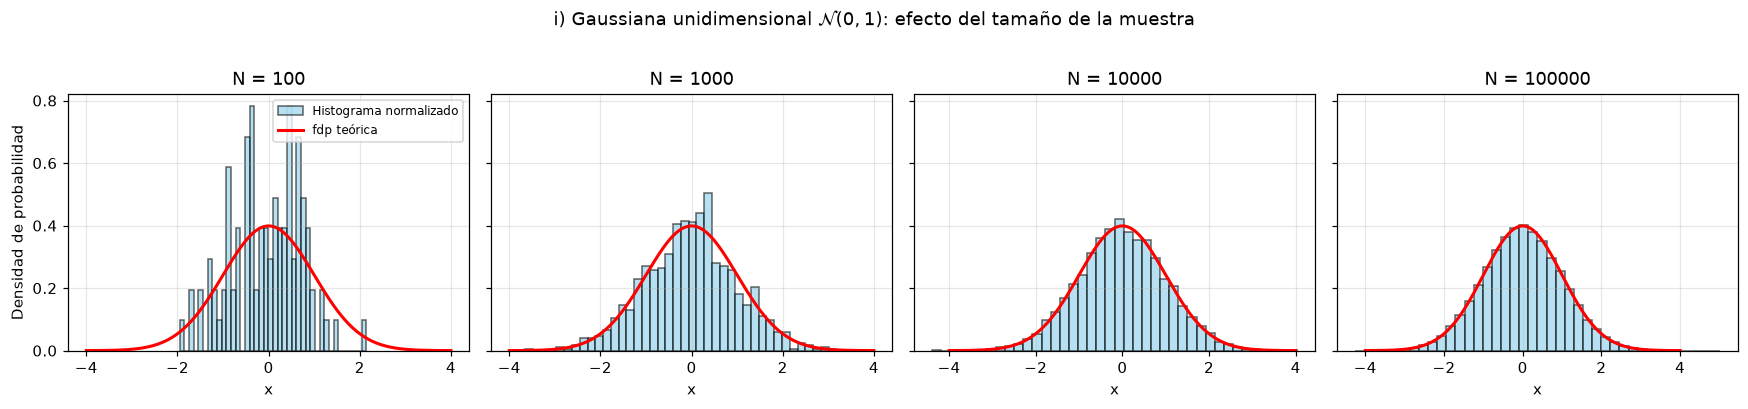

In [4]:
x_axis = np.linspace(mu_1d - 4*sigma_1d, mu_1d + 4*sigma_1d, 500)
pdf_teorica_1d = norm.pdf(x_axis, mu_1d, sigma_1d)

fig, axes = plt.subplots(1, len(Ns), figsize=(16, 3.6), sharey=True)
for ax, (N, x) in zip(axes, muestras_1d.items()):
    ax.hist(x, bins=40, density=True, alpha=0.6, color="skyblue", edgecolor="black",
            label="Histograma normalizado")
    ax.plot(x_axis, pdf_teorica_1d, "r-", lw=2, label="fdp teórica")
    ax.set_title(f"N = {N}")
    ax.set_xlabel("x")
axes[0].set_ylabel("Densidad de probabilidad")
axes[0].legend(fontsize=8)
fig.suptitle("i) Gaussiana unidimensional $\\mathcal{N}(0,1)$: efecto del tamaño de la muestra", y=1.02)
plt.tight_layout()
plt.show()

**Observaciones.** Con pocas muestras ($N=100$) el histograma es ruidoso y se aparta visiblemente de la campana teórica. A medida que $N$ crece, el histograma converge a la fdp teórica y la media y el desvío muestrales se acercan a $\mu$ y $\sigma$. Esto muestra que **la calidad de una estimación de la fdp depende críticamente de la cantidad de datos disponibles**.

### 1.4 Casos ii) y iii) fdp gaussiana bidimensional

Para aislar el efecto de la correlación se usan dos matrices de covarianza con **las mismas varianzas marginales** ($\sigma_1^2=2$, $\sigma_2^2=1$) y se cambia únicamente la covarianza entre variables. Ambos casos comparten el vector de medias $\boldsymbol{\mu}=(1,\,-1)^\top$.

- **ii) No correlacionada:** $\boldsymbol{\Sigma}=\begin{pmatrix}2 & 0\\ 0 & 1\end{pmatrix}$
- **iii) Correlacionada:** $\boldsymbol{\Sigma}=\begin{pmatrix}2 & 1.2\\ 1.2 & 1\end{pmatrix}$, con coeficiente de correlación $\rho=\dfrac{\sigma_{12}}{\sigma_1\sigma_2}=\dfrac{1.2}{\sqrt{2}\cdot 1}\approx 0.85$.

Se define una función auxiliar que, para cada caso:

1. genera las muestras (**a**),
2. estima la fdp con un histograma 2D normalizado (**b**),
3. superpone las curvas de nivel de la fdp teórica (**c**),
4. y dibuja además un *scatter* de las muestras con las elipses de $1\sigma$, $2\sigma$ y $3\sigma$ obtenidas de la descomposición en autovalores de $\boldsymbol{\Sigma}$.

In [5]:
def elipse_sigma(mu, Sigma, k, n=200):
    '''Puntos de la elipse de k desvíos: {x : (x-mu)^T Sigma^-1 (x-mu) = k^2}.'''
    lam, V = np.linalg.eigh(Sigma)                      # Sigma = V diag(lam) V^T
    t = np.linspace(0, 2*np.pi, n)
    circulo = np.vstack([np.cos(t), np.sin(t)])         # circunferencia unitaria
    return (mu[:, None] + k * V @ (np.sqrt(lam)[:, None] * circulo)).T


def estudiar_gaussiana_2d(mu, Sigma, N, titulo, rng):
    mu = np.asarray(mu, float)
    Sigma = np.asarray(Sigma, float)

    # a) generar muestras
    data = gaussiana_nd(mu, Sigma, N, rng)

    # Parámetros teóricos vs. muestrales
    lam, V = np.linalg.eigh(Sigma)
    eje_mayor = V[:, np.argmax(lam)]
    angulo = np.degrees(np.arctan2(eje_mayor[1], eje_mayor[0])) % 180
    print(titulo)
    print("  media teórica  :", mu, "| muestral:", data.mean(axis=0).round(3))
    print("  Sigma teórica  :", Sigma.tolist())
    print("  Sigma muestral :", np.cov(data.T).round(3).tolist())
    print("  autovalores    :", lam.round(3), f"| ángulo del eje mayor: {angulo:.1f}°")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

    # Panel izquierdo: muestras + elipses de nivel
    ax1.scatter(data[:, 0], data[:, 1], s=3, alpha=0.3, color="steelblue")
    for k, ls in zip([1, 2, 3], ["-", "--", ":"]):
        e = elipse_sigma(mu, Sigma, k)
        ax1.plot(e[:, 0], e[:, 1], "r", ls=ls, lw=1.5, label=f"{k}σ")
    ax1.plot(*mu, "k+", ms=12, mew=2)
    ax1.set_title("a) Muestras y elipses de nivel")
    ax1.legend()

    # Panel derecho: b) histograma 2D normalizado y c) fdp teórica
    h = ax2.hist2d(data[:, 0], data[:, 1], bins=50, density=True, cmap="Blues")
    fig.colorbar(h[3], ax=ax2, label="Densidad empírica")
    xg, yg = np.mgrid[mu[0]-4.5:mu[0]+4.5:.05, mu[1]-4.5:mu[1]+4.5:.05]
    pdf = multivariate_normal(mu, Sigma).pdf(np.dstack((xg, yg)))
    cs = ax2.contour(xg, yg, pdf, colors="red", linewidths=1.3)
    ax2.clabel(cs, inline=True, fontsize=8, fmt="%.2f")
    ax2.set_title("b) Histograma 2D normalizado  +  c) fdp teórica (contornos)")

    for ax in (ax1, ax2):
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
        ax.set_xlim(mu[0]-4.5, mu[0]+4.5); ax.set_ylim(mu[1]-4.5, mu[1]+4.5)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    return data

#### Caso ii) No correlacionada

ii) Gaussiana 2D no correlacionada
  media teórica  : [ 1. -1.] | muestral: [ 1.009 -1.007]
  Sigma teórica  : [[2.0, 0.0], [0.0, 1.0]]
  Sigma muestral : [[2.01, -0.029], [-0.029, 1.016]]
  autovalores    : [1. 2.] | ángulo del eje mayor: 0.0°


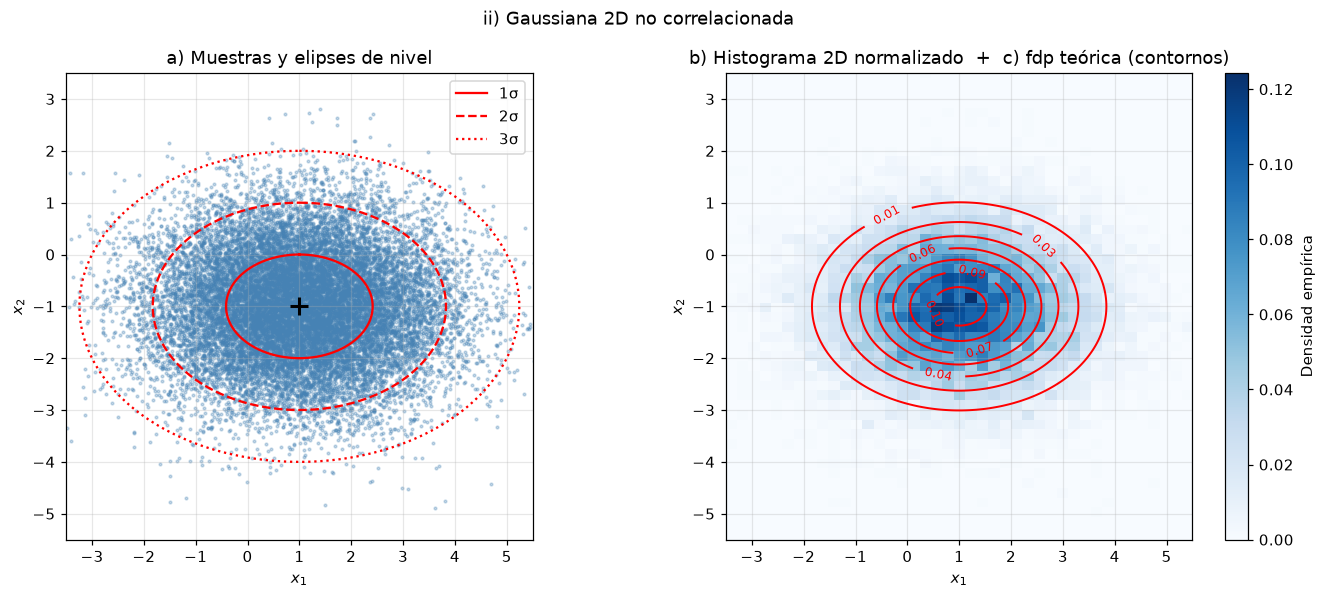

In [6]:
mu_2d = [1.0, -1.0]
Sigma_no_corr = [[2.0, 0.0],
                 [0.0, 1.0]]

data_no_corr = estudiar_gaussiana_2d(mu_2d, Sigma_no_corr, 20_000,
                                     "ii) Gaussiana 2D no correlacionada", rng)

Como $\boldsymbol{\Sigma}$ es diagonal, sus autovectores son los ejes coordenados: las elipses quedan **alineadas con $x_1$ y $x_2$** (ángulo $0°$) y están más estiradas en $x_1$ porque $\sigma_1^2>\sigma_2^2$. (Si además fuera $\sigma_1^2=\sigma_2^2$ se obtendrían circunferencias.)

#### Caso iii) Correlacionada

iii) Gaussiana 2D correlacionada
  media teórica  : [ 1. -1.] | muestral: [ 1.004 -0.989]
  Sigma teórica  : [[2.0, 1.2], [1.2, 1.0]]
  Sigma muestral : [[1.983, 1.199], [1.199, 1.008]]
  autovalores    : [0.2 2.8] | ángulo del eje mayor: 33.7°


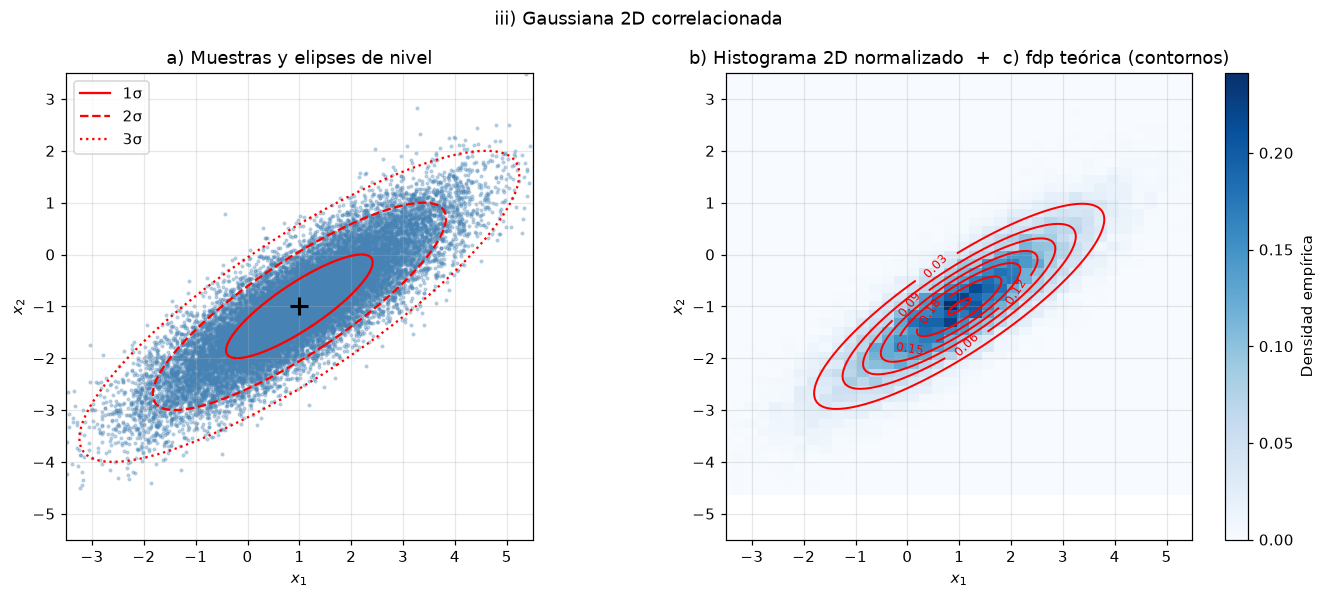

In [7]:
Sigma_corr = [[2.0, 1.2],
              [1.2, 1.0]]

data_corr = estudiar_gaussiana_2d(mu_2d, Sigma_corr, 20_000,
                                  "iii) Gaussiana 2D correlacionada", rng)

**Observaciones.** Con las mismas varianzas marginales, la covarianza positiva $\sigma_{12}=1.2$ **rota** las elipses: el eje mayor deja de ser horizontal y apunta en la dirección en que $x_1$ y $x_2$ crecen juntas. Las estimaciones muestrales de $\boldsymbol{\mu}$ y $\boldsymbol{\Sigma}$ coinciden con los valores teóricos, y los contornos de la fdp teórica siguen fielmente al histograma 2D.

> **Implicancia para aprendizaje automático.** Un modelo que ignore las covarianzas (por ejemplo, Naive Bayes gaussiano, que asume $\boldsymbol{\Sigma}$ diagonal) sólo puede representar elipses alineadas con los ejes, y no logra capturar las dependencias lineales entre características como la del caso iii).

---
## 2. Teorema del límite central

> *Compruebe numéricamente el teorema del límite central mediante la suma de números aleatorios con distribución uniforme.*

### 2.1 Marco teórico

**Teorema del límite central (TLC).** Sean $X_1,\dots,X_K$ variables aleatorias independientes e idénticamente distribuidas con media $\mu$ y varianza $\sigma^2$ finitas. Entonces la suma $S_K=\sum_{i=1}^{K}X_i$ cumple

$$
\frac{S_K-K\mu}{\sigma\sqrt{K}}\;\xrightarrow[K\to\infty]{d}\;\mathcal{N}(0,1),
$$

es decir, para $K$ grande $S_K\approx\mathcal{N}(K\mu,\,K\sigma^2)$, **sin importar la distribución original** de las $X_i$.

Para $X_i\sim\mathcal{U}(0,1)$: $\mu=\tfrac12$ y $\sigma^2=\tfrac1{12}$, por lo que se espera

$$
S_K \approx \mathcal{N}\!\left(\frac{K}{2},\;\frac{K}{12}\right).
$$

La distribución exacta de la suma de $K$ uniformes es la de **Irwin–Hall**. Para $K=1$ es la propia uniforme, y para $K=2$ es una **triangular** (hay más formas de obtener sumas centrales que extremas).

**Plan del experimento.** Para cada $K$ se generan $N$ realizaciones de $S_K$ (cada una es la suma de $K$ uniformes independientes), se grafica su histograma normalizado y se superpone la gaussiana $\mathcal{N}(K/2,\,K/12)$ que predice el TLC. Para cuantificar la convergencia, además de la inspección visual se calculan:

- el **exceso de curtosis** de $S_K$, que vale $0$ para una gaussiana. Para la suma de $K$ uniformes vale exactamente $-1.2/K$ (la uniforme tiene curtosis en exceso $-1.2$, y para sumas de variables iid ese valor se divide por $K$);
- el **estadístico de Kolmogorov–Smirnov** (máxima distancia entre la función de distribución empírica y la de la gaussiana teórica).

### 2.2 Simulación

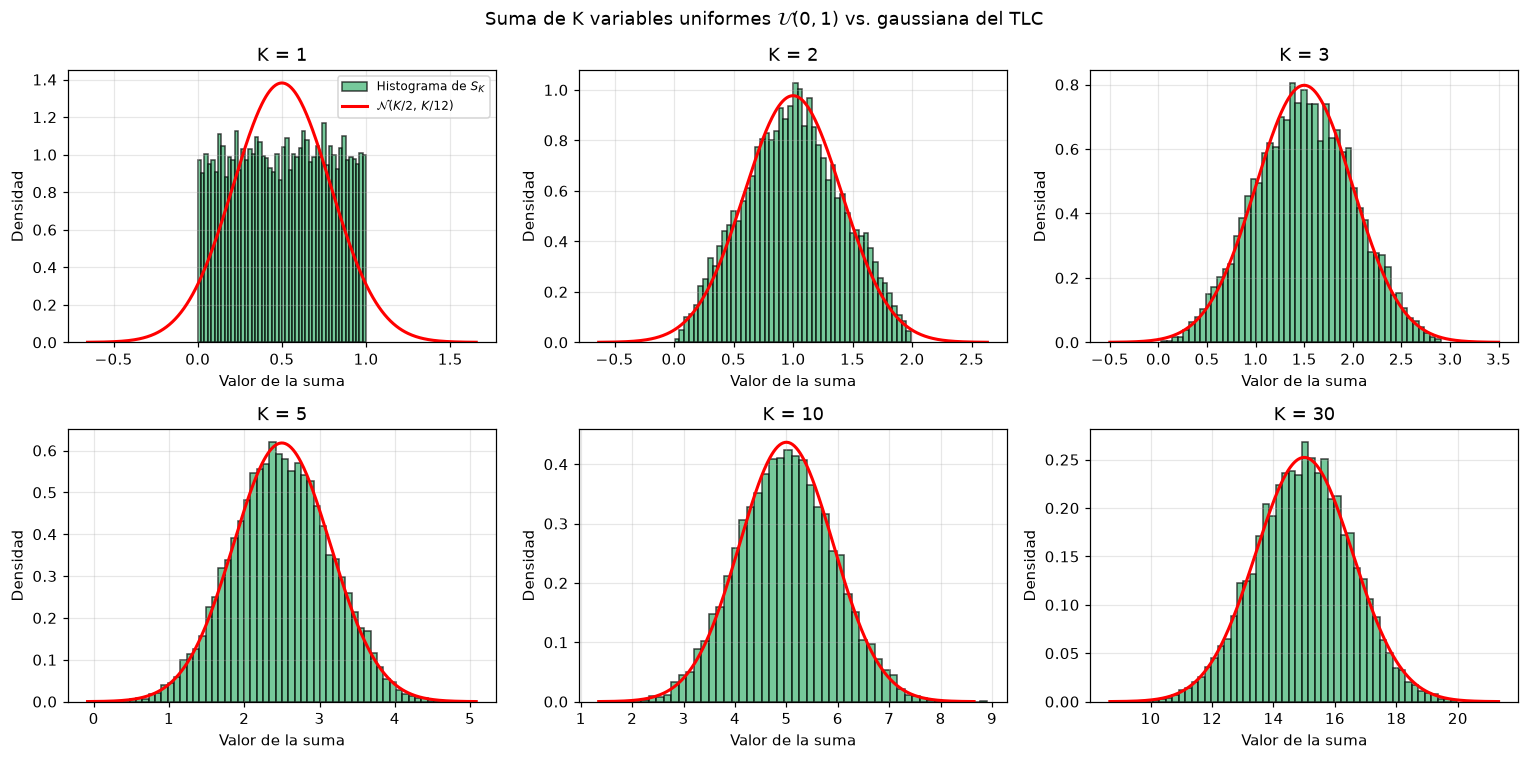

In [8]:
N_tlc = 10_000                    # cantidad de sumas generadas para cada K
K_graf = [1, 2, 3, 5, 10, 30]     # valores de K que se grafican

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, K in zip(axes.ravel(), K_graf):
    # Matriz (N, K) de uniformes independientes; se suma a lo largo de las K columnas
    S = rng.uniform(0, 1, (N_tlc, K)).sum(axis=1)

    mu_K, sigma_K = K/2, np.sqrt(K/12)           # parámetros que predice el TLC
    xs = np.linspace(mu_K - 4*sigma_K, mu_K + 4*sigma_K, 400)

    ax.hist(S, bins=50, density=True, color="mediumseagreen", edgecolor="black", alpha=0.7,
            label="Histograma de $S_K$")
    ax.plot(xs, norm.pdf(xs, mu_K, sigma_K), "r-", lw=2, label=r"$\mathcal{N}(K/2,\,K/12)$")
    ax.set_title(f"K = {K}")
    ax.set_xlabel("Valor de la suma")
    ax.set_ylabel("Densidad")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Suma de K variables uniformes $\\mathcal{U}(0,1)$ vs. gaussiana del TLC")
plt.tight_layout()
plt.show()

**Observaciones.**

- **$K=1$:** la densidad es la uniforme original (plana), sin ningún parecido con una campana.
- **$K=2$:** aparece la forma triangular (Irwin–Hall de orden 2).
- **$K=3$ y $K=5$:** la densidad ya es suave y se aproxima mucho a la campana.
- **$K\geq 10$:** el histograma es prácticamente indistinguible de la gaussiana teórica.

La convergencia es rápida porque la uniforme es simétrica y tiene colas acotadas. Distribuciones muy asimétricas o con colas pesadas necesitan más términos.

### 2.3 Cuantificación de la convergencia

Verificamos numéricamente lo anterior para un rango más amplio de $K$.

In [9]:
K_tabla = [1, 2, 5, 10, 20, 40, 80, 100, 200]

print(f"{'K':>5} | {'curtosis exc.':>13} | {'teórica -1.2/K':>14} | {'KS vs N(K/2,K/12)':>18}")
print("-" * 62)
for K in K_tabla:
    S = rng.uniform(0, 1, (N_tlc, K)).sum(axis=1)
    curt = stats.kurtosis(S)                                          # exceso de curtosis (Fisher)
    ks = stats.kstest(S, norm(K/2, np.sqrt(K/12)).cdf).statistic  # distancia de Kolmogorov-Smirnov
    print(f"{K:>5} | {curt:13.3f} | {-1.2/K:14.3f} | {ks:18.4f}")

    K | curtosis exc. | teórica -1.2/K |  KS vs N(K/2,K/12)
--------------------------------------------------------------
    1 |        -1.204 |         -1.200 |             0.0632
    2 |        -0.598 |         -0.600 |             0.0189
    5 |        -0.275 |         -0.240 |             0.0144
   10 |        -0.074 |         -0.120 |             0.0119
   20 |        -0.073 |         -0.060 |             0.0130
   40 |        -0.039 |         -0.030 |             0.0073
   80 |         0.018 |         -0.015 |             0.0053
  100 |        -0.039 |         -0.012 |             0.0074
  200 |        -0.007 |         -0.006 |             0.0078


La curtosis en exceso tiende a $0$ (valor de una gaussiana) siguiendo la ley $-1.2/K$. Los valores muestrales fluctúan alrededor de la curva teórica porque la curtosis es un estadístico ruidoso (con $N=10\,000$ su error típico es ~$\sqrt{24/N}\approx0.05$), por lo que para $K\gtrsim10$ ya no se distingue de cero. La distancia KS cae hasta el orden del **ruido estadístico** de usar $N=10\,000$ muestras (~$0.01$): a partir de ahí la suma no se puede distinguir de una gaussiana con estos datos.

> **Implicancia práctica.** El TLC justifica por qué el ruido de medición, o el error agregado en muchos conjuntos de datos reales, suele modelarse como gaussiano: es el resultado de la suma de numerosos efectos pequeños e independientes. Esto también explica el rol central que tiene la distribución gaussiana en el reconocimiento de patrones.

---
## 3. Entropía diferencial

> *Estime numéricamente y compare con el valor teórico la entropía de una variable aleatoria con distribución: i) laplaciana; ii) gaussiana y iii) uniforme.*

### 3.1 Marco teórico

La **entropía diferencial** de una variable aleatoria continua con fdp $p(x)$ mide la incertidumbre (o "sorpresa" promedio) asociada a ella:

$$
H(x) = -\int p(x)\,\ln p(x)\,dx = E\big[-\ln p(x)\big].
$$

(Con logaritmo natural se mide en *nats*; con $\log_2$, en *bits*.)

**Valores teóricos.** Para las tres distribuciones del ejercicio existen expresiones cerradas:

| Distribución | fdp | Entropía $H$ |
|:--|:--|:--|
| Gaussiana $\mathcal{N}(\mu,\sigma^2)$ | $\frac{1}{\sqrt{2\pi}\sigma}e^{-(x-\mu)^2/2\sigma^2}$ | $\tfrac12\ln(2\pi e\,\sigma^2)$ |
| Laplaciana $(\mu,b)$ | $\frac{1}{2b}e^{-\lvert x-\mu\rvert/b}$ | $1+\ln(2b)$ |
| Uniforme $\mathcal{U}(a,c)$ | $\frac{1}{c-a}$ en $[a,c]$ | $\ln(c-a)$ |

**Estimación numérica.** Como $H$ es una **esperanza**, la **ley de los grandes números** permite aproximarla con el promedio muestral. Dadas $T$ muestras $x_t\sim p(x)$ independientes:

$$
H(x) = E[-\ln p(x)]\;\approx\;-\frac{1}{T}\sum_{t=1}^{T}\ln p(x_t).
$$

Notar que este estimador **evalúa la fdp teórica en las muestras**, que son las que proveen la aleatoriedad. A medida que $T\to\infty$ el estimador converge al valor teórico, con un error típico que decae como $1/\sqrt{T}$.

### 3.2 Configuración

Se eligen los siguientes parámetros:

- Laplaciana: $\mu=0$, $b=1$ (varianza $2b^2=2$)
- Gaussiana: $\mu=0$, $\sigma=1$ (varianza $1$)
- Uniforme: $\mathcal{U}(-2,2)$ (varianza $4^2/12\approx1.33$)

Primero se contrastan las expresiones cerradas con el valor que informa `scipy`.

In [10]:
dist_laplace = laplace(loc=0.0, scale=1.0)
dist_norm    = norm(loc=0.0, scale=1.0)
dist_unif    = uniform(loc=-2.0, scale=4.0)       # uniforme en [-2, 2]

# Fórmulas cerradas
H_laplace_formula = 1 + np.log(2 * 1.0)                       # 1 + ln(2b)
H_norm_formula    = 0.5 * np.log(2 * np.pi * np.e * 1.0**2)   # 1/2 ln(2 pi e sigma^2)
H_unif_formula    = np.log(2.0 - (-2.0))                      # ln(c - a)

# Valores teóricos
H_teo = {"Laplaciana": dist_laplace.entropy(),
         "Gaussiana":  dist_norm.entropy(),
         "Uniforme":   dist_unif.entropy()}
H_formula = {"Laplaciana": H_laplace_formula,
             "Gaussiana":  H_norm_formula,
             "Uniforme":   H_unif_formula}

print(f"{'Distribución':<12} | {'fórmula (nats)':>14} | {'scipy (nats)':>12}")
for nombre in H_teo:
    print(f"{nombre:<12} | {H_formula[nombre]:14.4f} | {H_teo[nombre]:12.4f}")

Distribución | fórmula (nats) | scipy (nats)
Laplaciana   |         1.6931 |       1.6931
Gaussiana    |         1.4189 |       1.4189
Uniforme     |         1.3863 |       1.3863


### 3.3 Estimación numérica

Se generan $T=10^5$ muestras de cada distribución y se calcula el estimador $-\frac1t\sum_{i=1}^{t}\ln p(x_i)$ **de forma acumulada** para $t=1,\dots,T$, de modo de observar cómo evoluciona la estimación al aumentar la cantidad de datos.

In [11]:
T = 100_000
dists = {"Laplaciana": (dist_laplace, "blue"),
         "Gaussiana":  (dist_norm,    "red"),
         "Uniforme":   (dist_unif,    "green")}

muestras = {n: d.rvs(size=T, random_state=rng) for n, (d, _) in dists.items()}


def entropia_acumulada(x, dist):
    '''Estimación de H usando las primeras t muestras, para t = 1..len(x).'''
    sorpresa = -np.log(dist.pdf(x))              # -ln p(x_t)
    return np.cumsum(sorpresa) / np.arange(1, len(x) + 1)


trayectorias = {n: entropia_acumulada(muestras[n], d) for n, (d, _) in dists.items()}

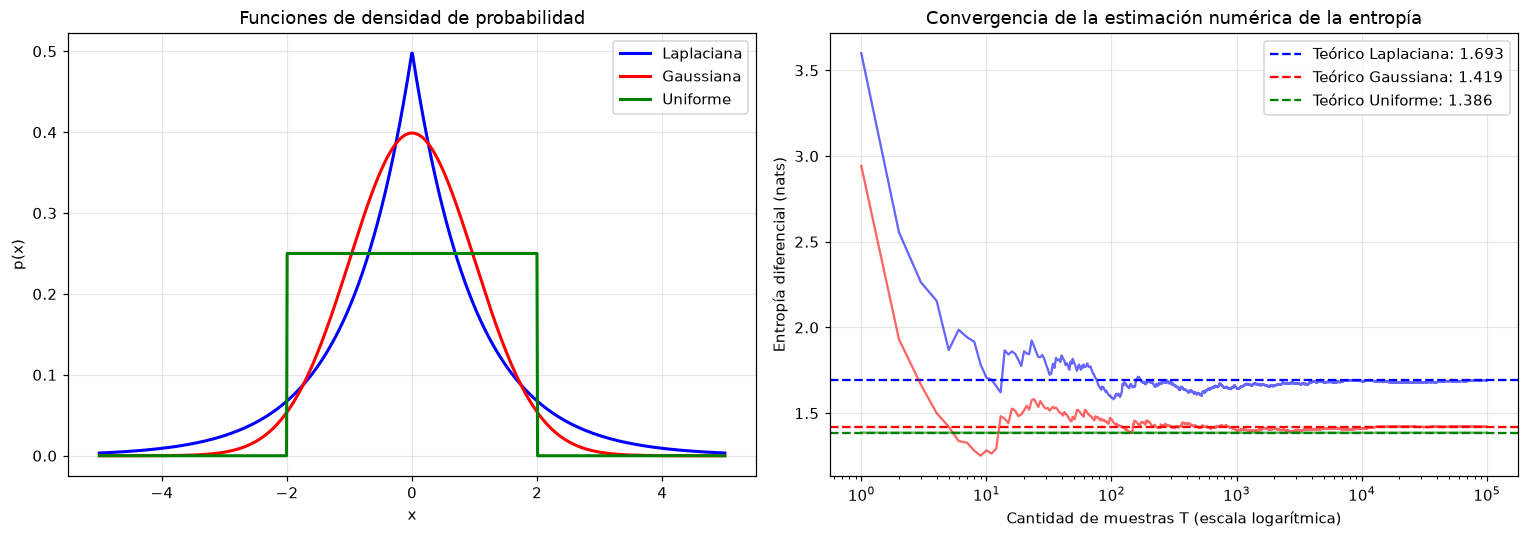

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Izquierda: las tres fdp
xs = np.linspace(-5, 5, 1000)
for n, (d, c) in dists.items():
    ax1.plot(xs, d.pdf(xs), color=c, lw=2, label=n)
ax1.set_title("Funciones de densidad de probabilidad")
ax1.set_xlabel("x"); ax1.set_ylabel("p(x)")
ax1.legend()

# Derecha: convergencia de la estimación
t = np.arange(1, T + 1)
for n, (d, c) in dists.items():
    ax2.plot(t, trayectorias[n], color=c, alpha=0.6)
    ax2.axhline(H_teo[n], color=c, ls="--", label=f"Teórico {n}: {H_teo[n]:.3f}")
ax2.set_xscale("log")
ax2.set_title("Convergencia de la estimación numérica de la entropía")
ax2.set_xlabel("Cantidad de muestras T (escala logarítmica)")
ax2.set_ylabel("Entropía diferencial (nats)")
ax2.legend()

plt.tight_layout()
plt.show()

### 3.4 Comparación numérica con el valor teórico

Se informa la estimación para distintos $T$ junto con el **error estándar** del estimador, calculado como $\hat\sigma/\sqrt{T}$, donde $\hat\sigma$ es el desvío muestral de la sorpresa $-\ln p(x_t)$.

In [13]:
T_vals = [10, 100, 1_000, 10_000, 100_000]

print(f"{'Distribución':<12} | " + " | ".join(f"T={tv:>6}" for tv in T_vals) + " |  teórico | error est. (T=1e5)")
print("-" * 100)
for n, (d, _) in dists.items():
    est = [trayectorias[n][tv - 1] for tv in T_vals]
    se = (-np.log(d.pdf(muestras[n]))).std(ddof=1) / np.sqrt(T)
    print(f"{n:<12} | " + " | ".join(f"{e:8.4f}" for e in est) + f" | {H_teo[n]:8.4f} | {se:.5f}")

Distribución | T=    10 | T=   100 | T=  1000 | T= 10000 | T=100000 |  teórico | error est. (T=1e5)
----------------------------------------------------------------------------------------------------
Laplaciana   |   1.7079 |   1.5899 |   1.6470 |   1.6882 |   1.6915 |   1.6931 | 0.00316
Gaussiana    |   1.2830 |   1.4654 |   1.3994 |   1.4108 |   1.4211 |   1.4189 | 0.00226
Uniforme     |   1.3863 |   1.3863 |   1.3863 |   1.3863 |   1.3863 |   1.3863 | 0.00000


**Observaciones.**

- Con $T=10^4$ las estimaciones ya están a ~$0.01$ del valor teórico, y con $T=10^5$ a ~$0.003$ o menos, consistente con el error estándar informado (del orden de $10^{-3}$).
- Con pocas muestras ($T<10^3$) las trayectorias de la gaussiana y de la laplaciana fluctúan mucho: el estimador es un promedio de pocas variables aleatorias. Se necesitan muchos datos para que la estimación sea confiable.
- **El caso uniforme es especial:** como $p(x)=1/4$ es **constante** en su soporte, la sorpresa $-\ln p(x_t)=\ln 4$ es la misma para todas las muestras, y el estimador da **exactamente** el valor teórico desde $T=1$ (error estándar nulo). Esto es coherente con que la uniforme maximiza la entropía entre las distribuciones con soporte acotado.
- La laplaciana, al tener colas más pesadas, produce sorpresas de mayor variabilidad y una convergencia algo más lenta que la gaussiana.

### 3.5 ¿Cuál distribución tiene mayor entropía?

En la comparación anterior, la laplaciana resulta ser la de mayor entropía ($\approx1.69$), seguida por la gaussiana ($\approx1.42$) y la uniforme ($\approx1.39$). **Pero esta comparación no es justa**: las tres distribuciones tienen **varianzas distintas** ($2$, $1$ y $1.33$ respectivamente), y la entropía diferencial crece con la dispersión.

El resultado clásico es que **la gaussiana es la distribución de máxima entropía entre todas las que tienen una media y varianza dadas**. Para verificarlo, comparamos las tres distribuciones con **igual varianza $\sigma^2=1$**:

- Gaussiana: $\sigma=1$.
- Laplaciana: $2b^2=1\Rightarrow b=1/\sqrt2$.
- Uniforme: $\frac{(c-a)^2}{12}=1\Rightarrow c-a=2\sqrt3$.

In [14]:
dists_iguales = {
    "Gaussiana":  norm(loc=0, scale=1.0),
    "Laplaciana": laplace(loc=0, scale=1/np.sqrt(2)),
    "Uniforme":   uniform(loc=-np.sqrt(3), scale=2*np.sqrt(3)),
}

print(f"{'Distribución':<12} | {'varianza':>8} | {'H teórica':>9} | {'H estimada (T=1e5)':>18}")
for n, d in dists_iguales.items():
    x = d.rvs(size=T, random_state=rng)
    H_est = -np.mean(np.log(d.pdf(x)))
    print(f"{n:<12} | {d.var():8.3f} | {d.entropy():9.4f} | {H_est:18.4f}")

Distribución | varianza | H teórica | H estimada (T=1e5)
Gaussiana    |    1.000 |    1.4189 |             1.4162
Laplaciana   |    1.000 |    1.3466 |             1.3468
Uniforme     |    1.000 |    1.2425 |             1.2425


Con igual varianza el orden se **invierte** respecto de la primera comparación: **Gaussiana > Laplaciana > Uniforme**. La gaussiana es la que más incertidumbre tiene para una dispersión dada, la laplaciana (más concentrada en torno a la media y con colas más largas) tiene menos, y la uniforme, que descarta por completo los valores fuera de su soporte, es la de menor entropía.

> **Implicancia.** La propiedad de máxima entropía de la gaussiana justifica usarla como el modelo "menos comprometido" cuando sólo se conocen la media y la varianza de los datos.

---
## 4. Conclusiones

1. **Generación y geometría de la gaussiana.** Un vector $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ se genera como $\boldsymbol{\mu}+\mathbf{L}\mathbf{z}$ con $\boldsymbol{\Sigma}=\mathbf{L}\mathbf{L}^\top$ y $\mathbf{z}\sim\mathcal{N}(\mathbf{0},\mathbf{I})$. El histograma normalizado converge a la fdp teórica al aumentar $N$. La matriz $\boldsymbol{\Sigma}$ determina la forma de la densidad: diagonal $\Rightarrow$ elipses alineadas con los ejes; términos fuera de la diagonal $\Rightarrow$ elipses rotadas según los autovectores de $\boldsymbol{\Sigma}$.
2. **Teorema del límite central.** La suma de $K$ uniformes pasa de una densidad plana ($K=1$) a una triangular ($K=2$) y converge rápidamente a la gaussiana $\mathcal{N}(K/2,K/12)$. Con $K\gtrsim10$ ya es indistinguible de ella, con una curtosis en exceso que decae como $-1.2/K$.
3. **Entropía diferencial.** Al ser $H=E[-\ln p(x)]$, se estima con el promedio muestral de la sorpresa (ley de los grandes números). Converge al valor teórico con un error del orden de $1/\sqrt{T}$, y para pocas muestras es inestable. En el caso uniforme la estimación es exacta, pues la sorpresa es constante. Para una misma varianza la gaussiana es la de máxima entropía.